# TS8 - Filtrado no lineal de ECG

Se usa otra vez el registro `ecg.mat` de la TS5 y la TS7 ($f_s = 1$ kHz, 1903 latidos).

En la TS7 lo más difícil fue sacar el movimiento de línea de base (oscilaciones por debajo de 0.5 Hz), y para lograrlo el pasa-banda terminó achicando las ondas P y T. Acá, en vez de filtrar, se estima la línea de base $\hat{b}$ y se la resta:

$$\hat{x} = s - \hat{b}$$

Se prueban dos estimadores (mediana y splines) y al final se arma un detector de latidos con un filtro adaptado.

In [1]:
import time
import numpy as np
import scipy.io as sio
import scipy.signal as sig
import scipy.ndimage as ndi
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

In [2]:
mat = sio.loadmat('../Extra/TS5/ECG_TP4.mat')   # = ecg.mat del repositorio jupytest

fs           = 1000
ecg_lead     = mat['ecg_lead'].flatten().astype(float)
qrs_pattern1 = mat['qrs_pattern1'].flatten().astype(float)
qrs_det      = mat['qrs_detections'].flatten().astype(int)

cant_muestras = len(ecg_lead)
n = np.arange(cant_muestras)
print(f'ECG: N={cant_muestras} muestras  ->  {cant_muestras/fs/60:.2f} min   (fs={fs} Hz)')
print(f'Latidos anotados (qrs_detections): {len(qrs_det)}')
print(f'Patron qrs_pattern1: {len(qrs_pattern1)} muestras ({len(qrs_pattern1)/fs*1000:.0f} ms)')

ECG: N=1129116 muestras  ->  18.82 min   (fs=1000 Hz)
Latidos anotados (qrs_detections): 1903
Patron qrs_pattern1: 113 muestras (113 ms)


## 1) Filtro de mediana

$$\hat{b} = \underset{600}{med}\left(\underset{200}{med}(s)\right)$$

La mediana ignora los eventos que ocupan menos de la mitad de la ventana. La de 200 ms elimina el QRS y la onda P, y la de 600 ms elimina la onda T. Lo que queda es la variación lenta de la señal, o sea la línea de base. A diferencia de la TS7, acá no hay frecuencia de corte: se elimina según la duración, así que las ondas P y T no se ven afectadas.

Se usó `scipy.ndimage.median_filter` con 201 y 601 muestras (la ventana tiene que ser impar). La función de scipy centra la ventana, mientras que la fórmula de la consigna es causal; la diferencia es solo un retardo de 400 ms, que no importa porque la señal ya está grabada.

In [3]:
win1 = int(0.200 * fs) | 1     # 201 muestras
win2 = int(0.600 * fs) | 1     # 601 muestras

t0 = time.perf_counter()
m_200 = ndi.median_filter(ecg_lead, size=win1)
b_med = ndi.median_filter(m_200,   size=win2)
t_med = time.perf_counter() - t0

x_med = ecg_lead - b_med
print(f'Ventanas de mediana: {win1} y {win2} muestras')
print(f'Tiempo de computo: {t_med:.2f} s')

Ventanas de mediana: 201 y 601 muestras
Tiempo de computo: 0.28 s


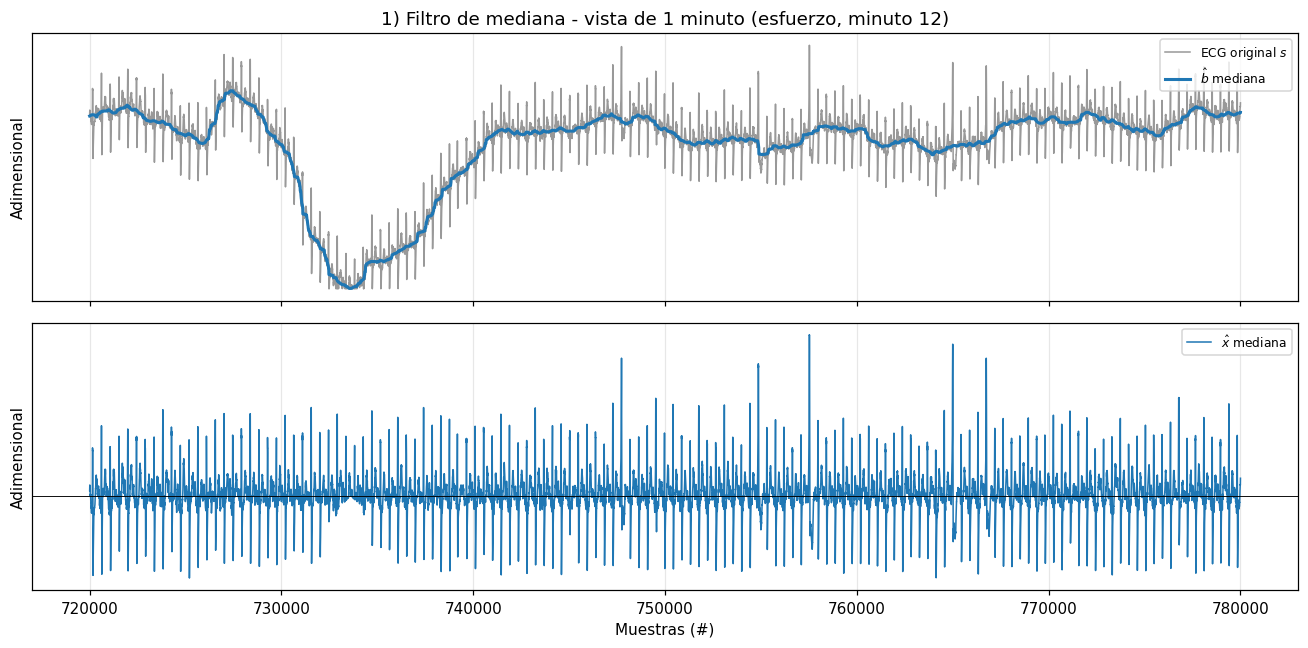

In [4]:
def plot_region(ii, titulo, estimaciones):
    # estimaciones: lista de (nombre, b_hat, color)
    i0, i1 = int(max(0, ii[0])), int(min(cant_muestras, ii[1]))
    z = np.arange(i0, i1)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    ax1.plot(z, ecg_lead[z], color='0.6', lw=1.0, label='ECG original $s$')
    for nombre, b, c in estimaciones:
        ax1.plot(z, b[z], color=c, lw=2.0, label=r'$\hat{b}$ ' + nombre)
    ax1.set(title=titulo, ylabel='Adimensional'); ax1.set_yticks(())
    ax1.grid(alpha=0.3); ax1.legend(fontsize=8, loc='upper right')
    for nombre, b, c in estimaciones:
        ax2.plot(z, ecg_lead[z] - b[z], color=c, lw=1.0, label=r'$\hat{x}$ ' + nombre)
    ax2.axhline(0, color='k', lw=0.6)
    ax2.set(xlabel='Muestras (#)', ylabel='Adimensional'); ax2.set_yticks(())
    ax2.grid(alpha=0.3); ax2.legend(fontsize=8, loc='upper right')
    plt.tight_layout(); plt.show()

# vista larga: 1 minuto alrededor del pico de esfuerzo
plot_region([int(12*60*fs), int(13*60*fs)],
            '1) Filtro de mediana - vista de 1 minuto (esfuerzo, minuto 12)',
            [('mediana', b_med, 'C0')])

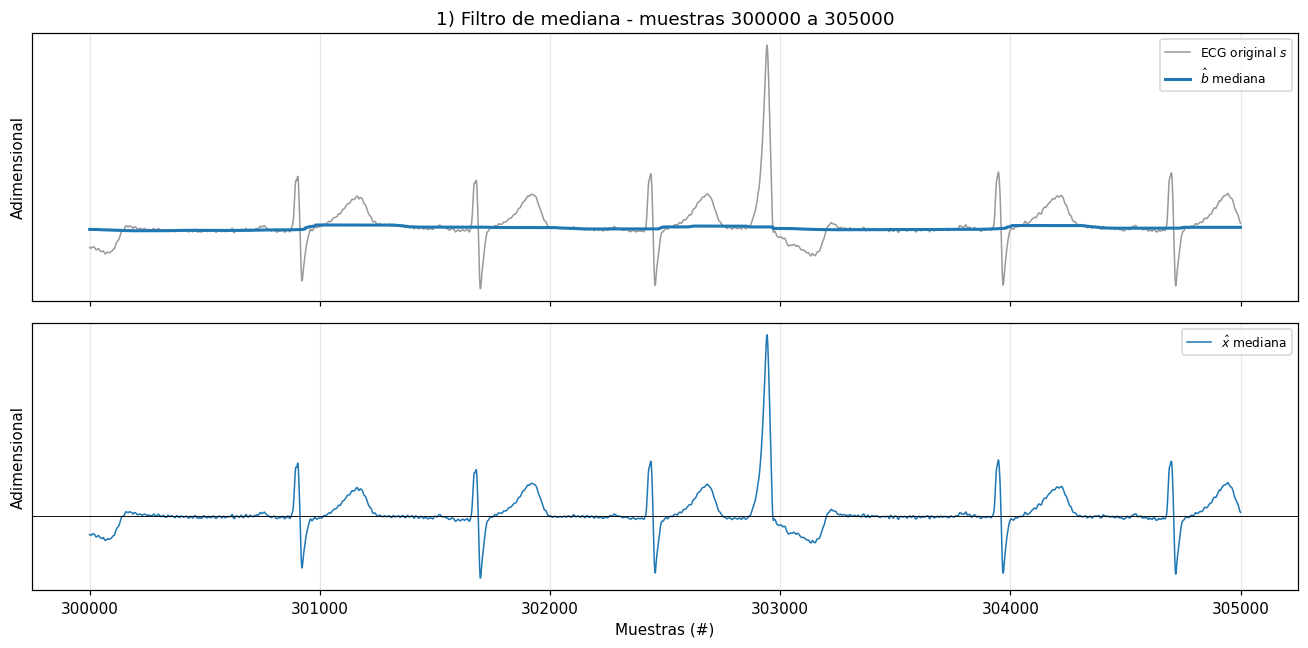

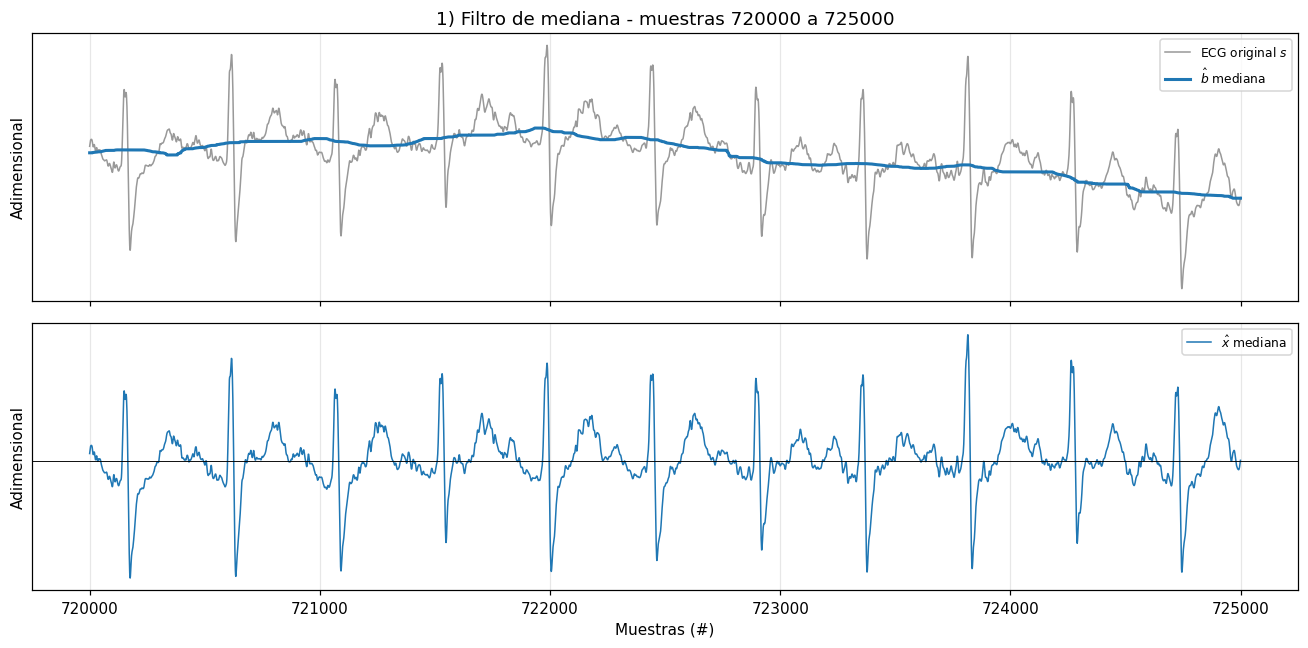

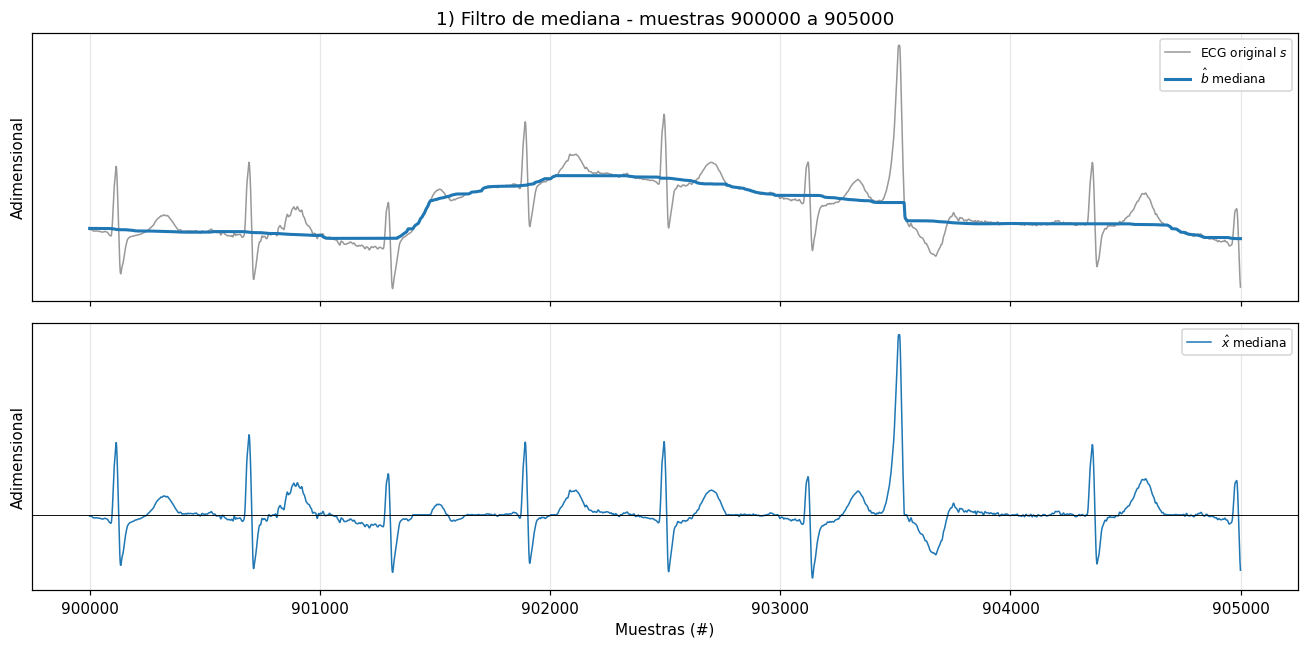

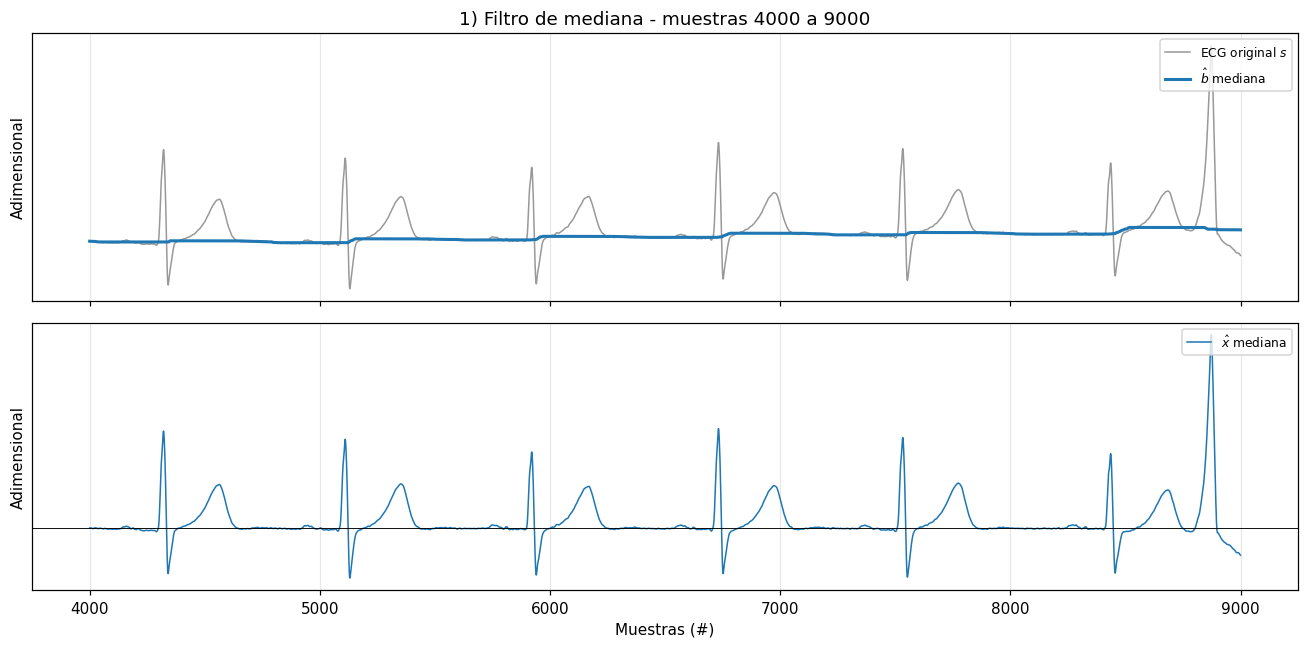

In [5]:
# zoom: 3 regiones de esfuerzo (las mismas de la TS7) y una de reposo
regiones = (
    [int( 5 * 60 * fs), int( 5 * 60 * fs) + 5000],
    [int(12 * 60 * fs), int(12 * 60 * fs) + 5000],
    [int(15 * 60 * fs), int(15 * 60 * fs) + 5000],
    [4000, 9000],
)
for ii in regiones:
    plot_region(ii, f'1) Filtro de mediana - muestras {ii[0]} a {ii[1]}',
                [('mediana', b_med, 'C0')])

$\hat{b}$ sigue la deriva sin rastros de los latidos, y al restarla el ECG queda sobre una línea plana con las ondas P y T intactas. Durante el esfuerzo, como la onda T ocupa más lugar en cada ventana, la estimación sube un poco y queda un pequeño corrimiento en $\hat{x}$.

## 2) Interpolación mediante splines cúbicos

En el segmento PQ el corazón casi no tiene actividad eléctrica, así que lo que vale $s$ ahí es prácticamente la línea de base. Retrocediendo un tiempo $n_0$ desde cada detección $n_i$ se obtienen los puntos

$$\mathcal{S} = \{(m_i,\ s(m_i))\ |\ i = 1, \dots, Q\}, \qquad m_i = n_i - n_0$$

que se interpolan con splines cúbicos en todo el registro:

$$\hat{b}(n) = \text{spline}_3(\mathcal{S}, n) \quad | \quad n = 1, \dots, N$$

Para elegir $n_0$ se armó un latido promedio y se buscó un tramo plano antes del QRS.

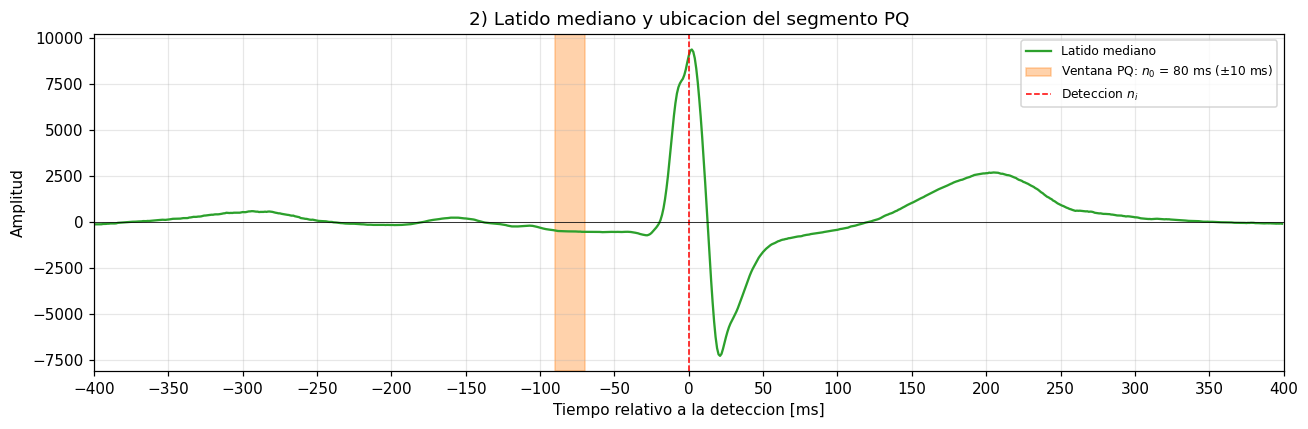

In [6]:
pre, post = 400, 400
latidos = np.array([ecg_lead[d-pre:d+post] - np.median(ecg_lead[d-pre:d+post])
                    for d in qrs_det if d-pre >= 0 and d+post <= cant_muestras])
lat_med = np.median(latidos, axis=0)
t_lat   = np.arange(-pre, post)

n0     = 80      # ms antes de la deteccion
semi_w = 10      # semi-ancho de la ventana de promediado [muestras]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(t_lat, lat_med, color='C2', lw=1.5, label='Latido mediano')
ax.axvspan(-n0-semi_w, -n0+semi_w, color='C1', alpha=0.35,
           label=f'Ventana PQ: $n_0$ = {n0} ms ($\\pm${semi_w} ms)')
ax.axvline(0, color='r', ls='--', lw=1, label='Deteccion $n_i$')
ax.axhline(0, color='k', lw=0.5)
ax.set(title='2) Latido mediano y ubicacion del segmento PQ', xlabel='Tiempo relativo a la deteccion [ms]',
       ylabel='Amplitud', xlim=(-400, 400))
ax.set_xticks(range(-400, 401, 50)); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

El tramo plano va de −100 a −35 ms antes de la detección, así que se eligió $n_0 = 80$ ms. En cada $m_i$ se tomó la mediana de 21 ms en lugar de una sola muestra, para reducir el efecto del ruido. Antes del primer latido y después del último se dejó fijo el último valor, para que el spline no se dispare.

In [7]:
m_i = qrs_det - n0
s_mi = np.array([np.median(ecg_lead[k-semi_w:k+semi_w+1]) for k in m_i])

t0 = time.perf_counter()
spl   = CubicSpline(m_i, s_mi)
b_spl = spl(n)
b_spl[:m_i[0]]  = s_mi[0]
b_spl[m_i[-1]:] = s_mi[-1]
t_spl = time.perf_counter() - t0

x_spl = ecg_lead - b_spl
print(f'Puntos de interpolacion Q = {len(m_i)}')
print(f'Tiempo de computo: {t_spl:.2f} s')

Puntos de interpolacion Q = 1903
Tiempo de computo: 0.03 s


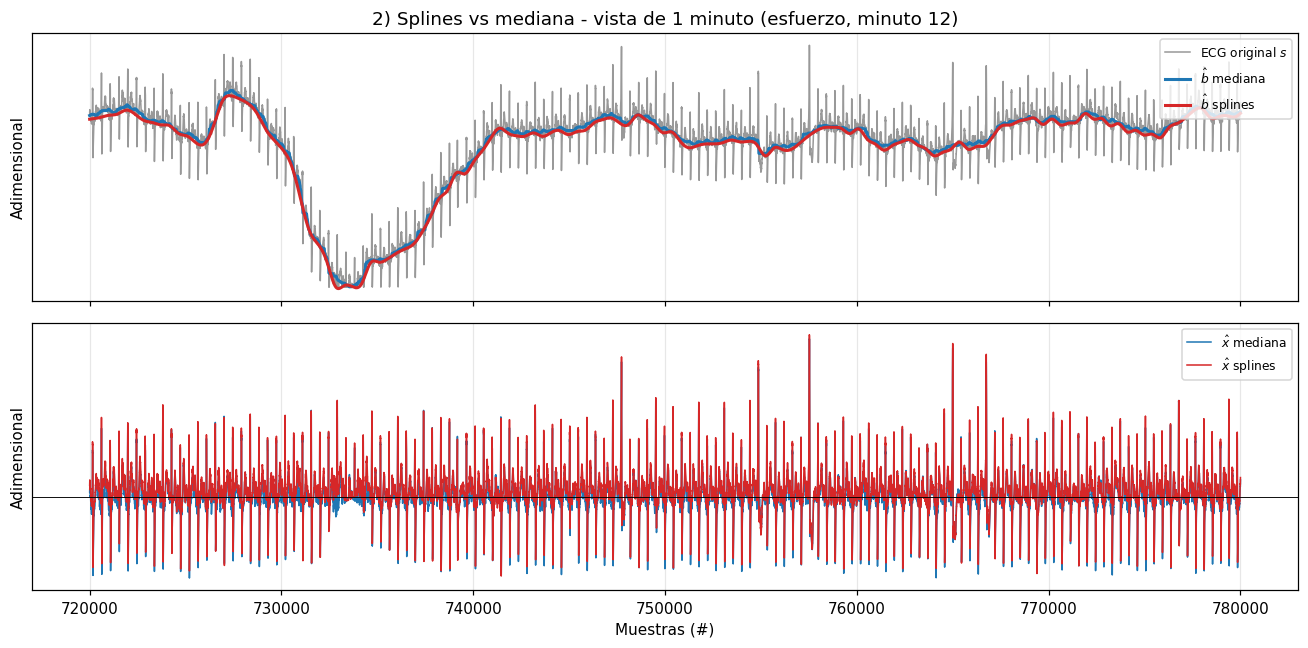

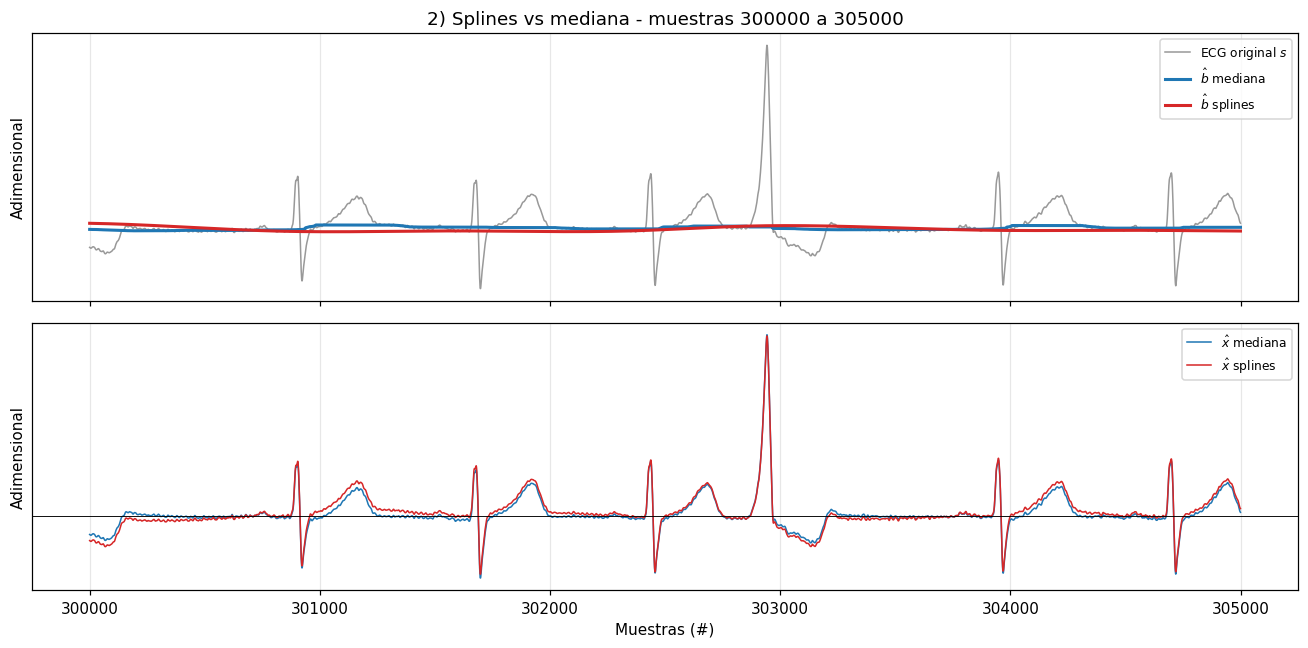

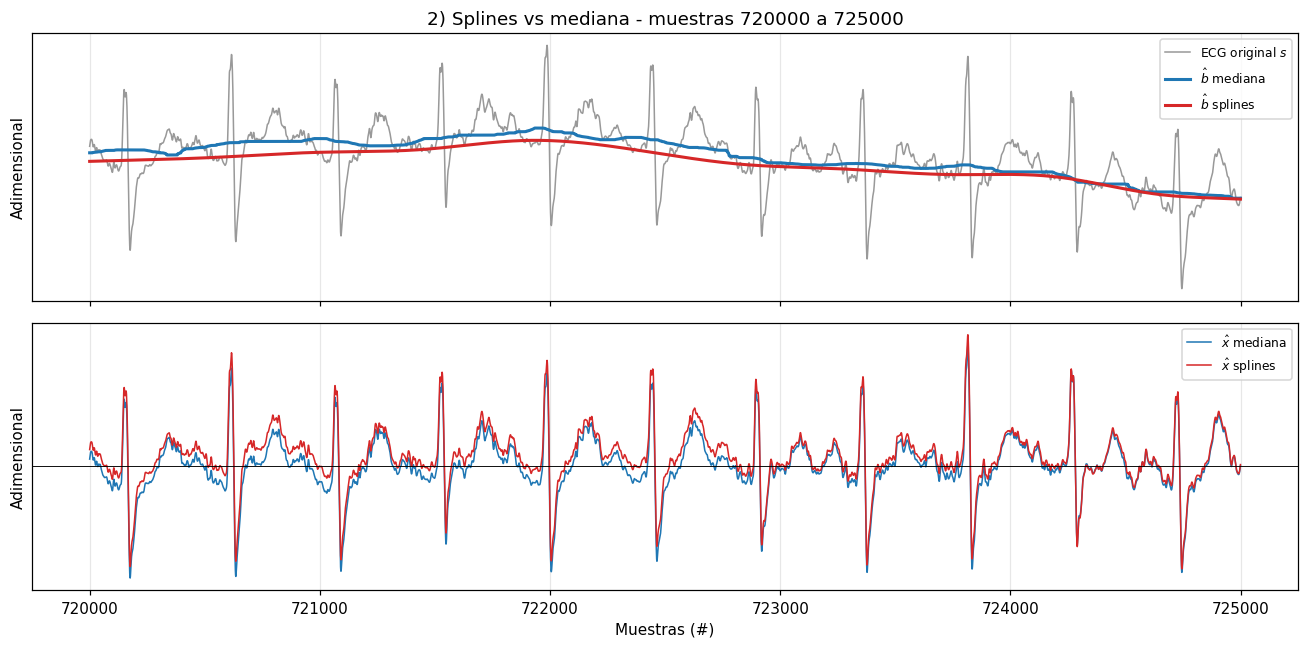

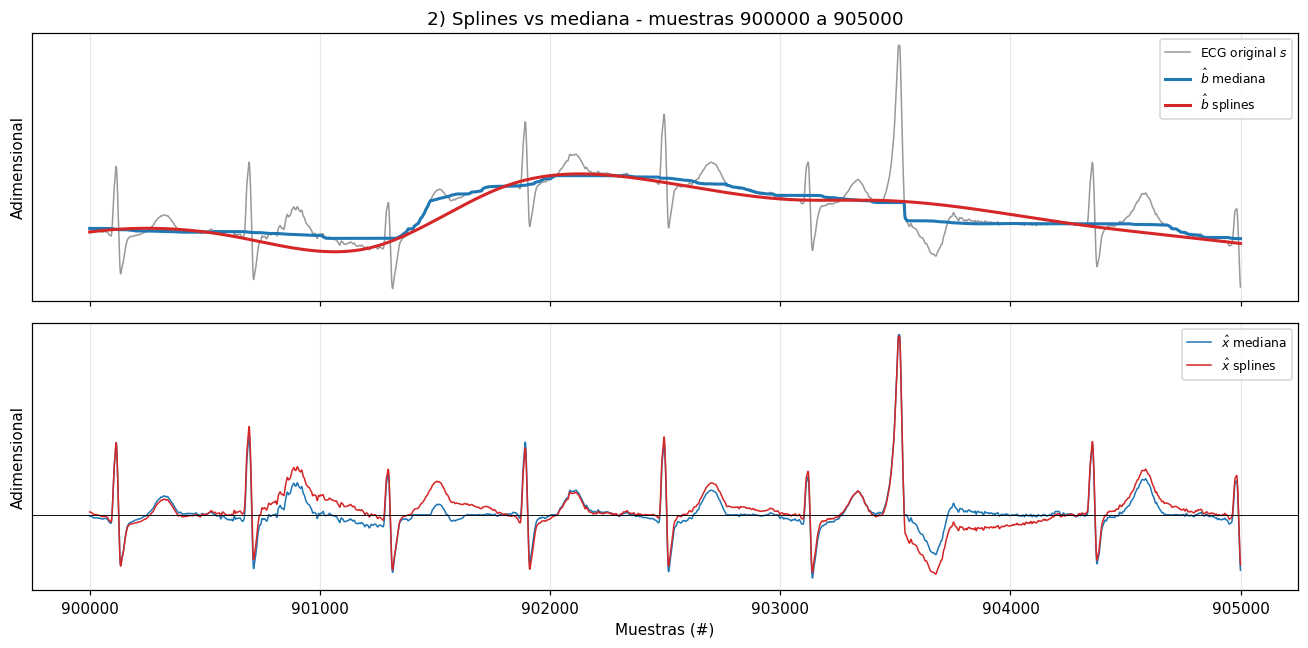

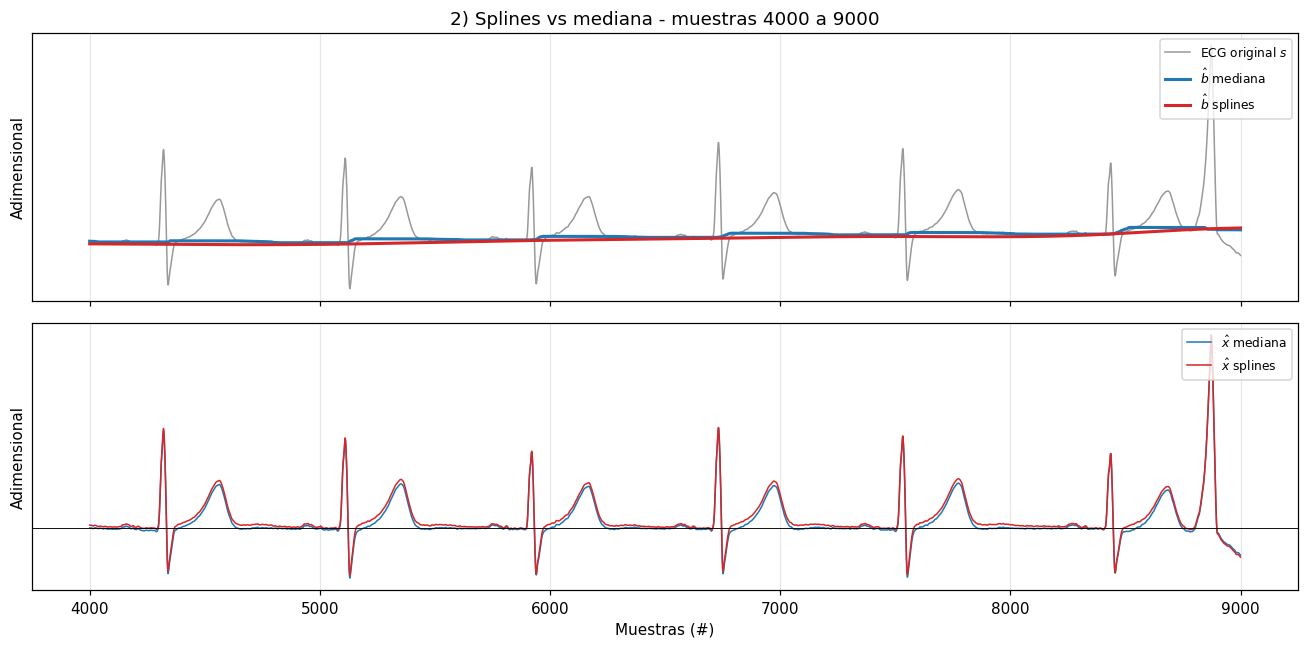

In [8]:
plot_region([int(12*60*fs), int(13*60*fs)],
            '2) Splines vs mediana - vista de 1 minuto (esfuerzo, minuto 12)',
            [('mediana', b_med, 'C0'), ('splines', b_spl, 'C3')])

for ii in regiones:
    plot_region(ii, f'2) Splines vs mediana - muestras {ii[0]} a {ii[1]}',
                [('mediana', b_med, 'C0'), ('splines', b_spl, 'C3')])

### Comparación de ambos estimadores

Se midió la potencia que queda en $\hat{x}$ por debajo de 0.5 Hz y el desvío de $\hat{x}$ en el segmento PQ de cada latido (debería ser cercano a cero). Esta última medida favorece a los splines, porque pasan justo por esos puntos.

In [9]:
def metricas(x):
    f, P = sig.welch(x, fs=fs, window='hann', nperseg=2**16)
    df = f[1] - f[0]
    pot_bl = P[(f > 0) & (f < 0.5)].sum() * df
    iso = np.array([np.median(x[k-semi_w:k+semi_w+1]) for k in m_i])
    return pot_bl, iso.std()

pot_s, iso_s = metricas(ecg_lead)
print(f'{"Senal":<22}{"Pot. < 0.5 Hz":>16}{"(rel. a s)":>12}{"std nivel PQ":>15}')
for nombre, x in [('s (original)', ecg_lead), ('x_hat mediana', x_med), ('x_hat splines', x_spl)]:
    pot, iso = metricas(x)
    print(f'{nombre:<22}{pot:16.3e}{10*np.log10(pot/pot_s):10.1f} dB{iso:15.1f}')

rms_dif = np.sqrt(np.mean((b_med - b_spl)**2))
print(f'\nRMS(b_mediana - b_splines) = {rms_dif:.0f}   (desvio del ECG = {ecg_lead.std():.0f})')

Senal                    Pot. < 0.5 Hz  (rel. a s)   std nivel PQ
s (original)                 1.193e+07       0.0 dB         4048.0
x_hat mediana                3.544e+04     -25.3 dB          517.3
x_hat splines                2.055e+05     -17.6 dB            9.7

RMS(b_mediana - b_splines) = 709   (desvio del ECG = 4915)


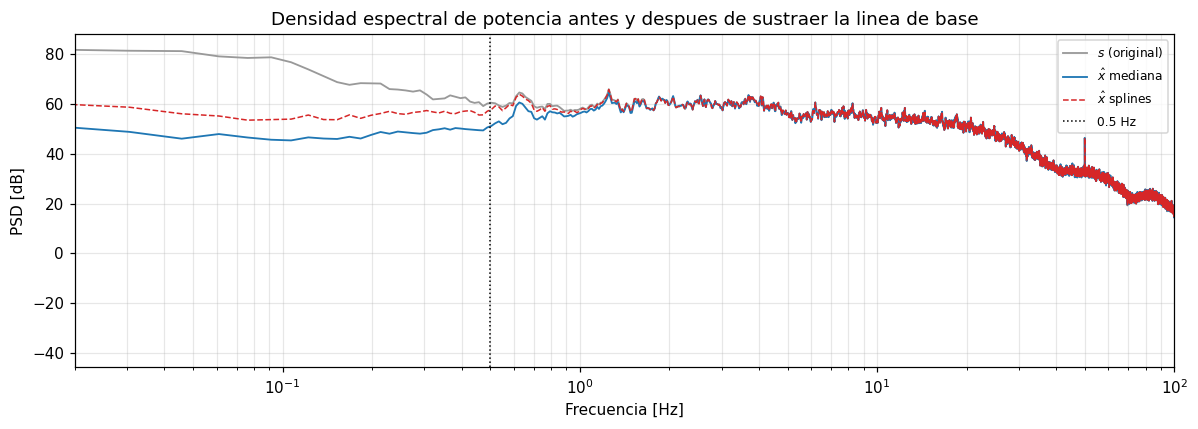

In [10]:
f_s, P_s = sig.welch(ecg_lead, fs=fs, nperseg=2**16)
f_m, P_m = sig.welch(x_med,    fs=fs, nperseg=2**16)
f_p, P_p = sig.welch(x_spl,    fs=fs, nperseg=2**16)

fig, ax = plt.subplots(figsize=(11, 4))
ax.semilogx(f_s, 10*np.log10(P_s), color='0.6', lw=1.2, label='$s$ (original)')
ax.semilogx(f_m, 10*np.log10(P_m), color='C0',  lw=1.2, label=r'$\hat{x}$ mediana')
ax.semilogx(f_p, 10*np.log10(P_p), color='C3',  lw=1.0, ls='--', label=r'$\hat{x}$ splines')
ax.axvline(0.5, color='k', ls=':', lw=1, label='0.5 Hz')
ax.set(title='Densidad espectral de potencia antes y despues de sustraer la linea de base',
       xlabel='Frecuencia [Hz]', ylabel='PSD [dB]', xlim=(0.02, 100))
ax.grid(alpha=0.3, which='both'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Los dos métodos bajan la potencia por debajo de 0.5 Hz (25 dB la mediana y 18 dB los splines), y por encima de 1 Hz el espectro queda igual al original, es decir que no alteran el ECG.

La mediana solo necesita la señal y aguanta bien los artefactos cortos, aunque parte de lo que saca es contenido lento del propio latido. Los splines siguen el nivel isoeléctrico real, pero tienen un solo punto por latido y dependen de que las detecciones sean buenas.

## 3) Filtro adaptado (matched filter)

### a) Detector de latidos

El filtro adaptado es el que mejor detecta una forma de onda conocida $p[n]$ en ruido blanco. Su respuesta al impulso es el patrón invertido, $h[n] = p[L-1-n]$, así que filtrar equivale a correlacionar la señal con el patrón: la salida es grande donde la señal se parece al patrón.

El detector consiste en:

1. Restarle la media a `qrs_pattern1`, para que la línea de base no genere salida.
2. Correlacionar el ECG con el patrón y normalizar la salida.
3. Buscar los picos que superan un umbral $\gamma$, con al menos 300 ms entre detecciones.
4. Corregir el corrimiento entre el pico de la salida y el pico R.

Es simple, barato (un FIR de 113 coeficientes) y más robusto al ruido que un umbral sobre el ECG, porque usa la forma completa del QRS. Como limitaciones, el ruido del ECG no es blanco, los latidos con forma distinta al patrón (por ejemplo los ventriculares) pueden perderse, y la salida depende de la amplitud, así que un artefacto grande puede dar un falso positivo. Además, el umbral es siempre un compromiso entre detectar todo y no meter detecciones falsas.

### b) Detección y evaluación

Una detección a menos de 30 ms de un latido de referencia es un verdadero positivo (TP); las que sobran son falsos positivos (FP) y los latidos sin detección son falsos negativos (FN).

$$\text{Se} = \frac{TP}{TP + FN} \qquad \text{PPV} = \frac{TP}{TP + FP} \qquad F_1 = \frac{2\, \text{Se} \cdot \text{PPV}}{\text{Se} + \text{PPV}}$$

In [11]:
patron = qrs_pattern1 - qrs_pattern1.mean()
L = len(patron)
demora_mf = L // 2 - int(np.argmax(qrs_pattern1))   # pico de y vs pico R
print(f'Patron: L={L}, maximo en la muestra {np.argmax(qrs_pattern1)} -> demora a compensar = {demora_mf} muestras')

def filtro_adaptado(x):
    y = np.correlate(x - np.median(x), patron, mode='same')
    return y / np.abs(y).max()

def detectar(y, umbral, refractario=0.3):
    pk, _ = sig.find_peaks(y, height=umbral, distance=int(refractario * fs))
    return pk - demora_mf

def evaluar(det, ref, tol=30):
    ref = np.sort(ref); usado = np.zeros(len(ref), bool)
    tp_idx = []
    for d in det:
        i = np.searchsorted(ref, d)
        cand = [j for j in (i-1, i) if 0 <= j < len(ref) and not usado[j] and abs(ref[j] - d) <= tol]
        if cand:
            j = min(cand, key=lambda j: abs(ref[j] - d)); usado[j] = True; tp_idx.append(d)
    tp = len(tp_idx); fp = len(det) - tp; fn = len(ref) - tp
    se, ppv = tp / (tp + fn), tp / (tp + fp)
    return dict(TP=tp, FP=fp, FN=fn, Se=se, PPV=ppv, F1=2*se*ppv/(se+ppv),
                fn_pos=ref[~usado], fp_pos=np.setdiff1d(det, tp_idx))

y_s   = filtro_adaptado(ecg_lead)    # sobre el ECG crudo
y_med = filtro_adaptado(x_med)       # sobre el ECG sin linea de base (punto 1)

Patron: L=113, maximo en la muestra 43 -> demora a compensar = 13 muestras


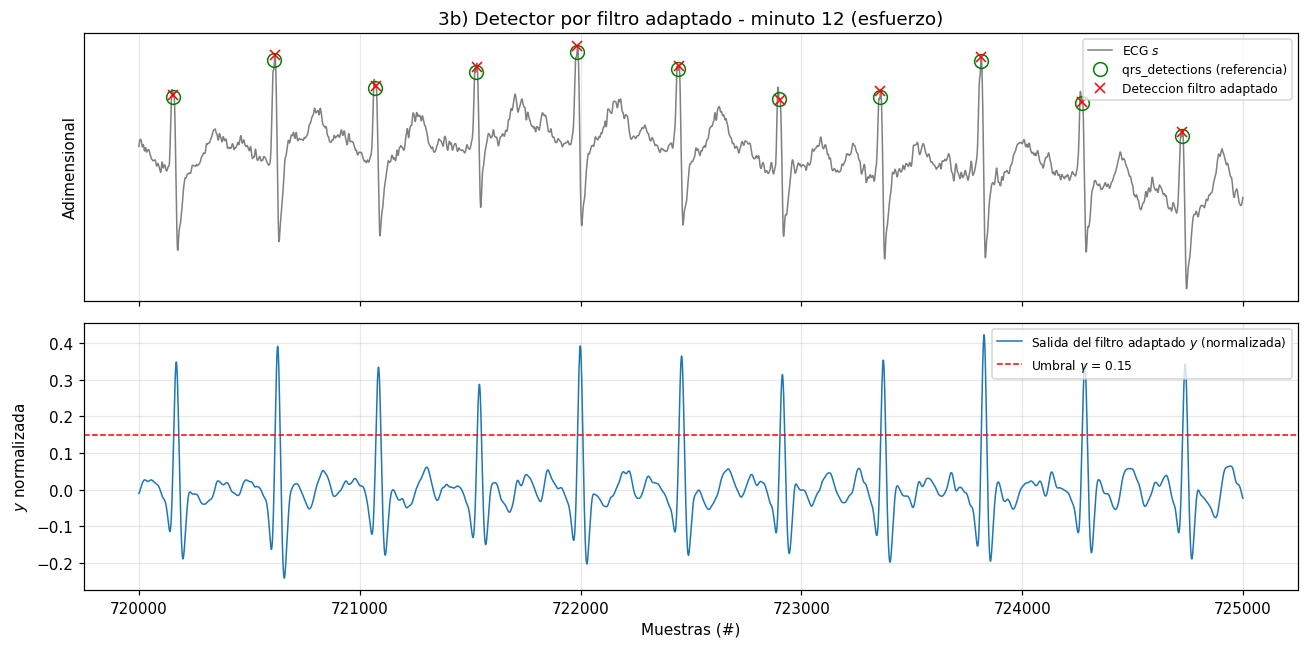

In [12]:
z = np.arange(int(12*60*fs), int(12*60*fs) + 5000)
det_demo = detectar(y_s, 0.15)
dz  = det_demo[(det_demo >= z[0]) & (det_demo < z[-1])]
rz  = qrs_det[(qrs_det >= z[0]) & (qrs_det < z[-1])]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(z, ecg_lead[z], color='0.5', lw=1, label='ECG $s$')
ax1.plot(rz, ecg_lead[rz], 'go', ms=9, mfc='none', label='qrs_detections (referencia)')
ax1.plot(dz, ecg_lead[dz], 'rx', ms=7, label='Deteccion filtro adaptado')
ax1.set(title='3b) Detector por filtro adaptado - minuto 12 (esfuerzo)', ylabel='Adimensional')
ax1.set_yticks(()); ax1.grid(alpha=0.3); ax1.legend(fontsize=8, loc='upper right')
ax2.plot(z, y_s[z], color='C0', lw=1, label='Salida del filtro adaptado $y$ (normalizada)')
ax2.axhline(0.15, color='r', ls='--', lw=1, label=r'Umbral $\gamma$ = 0.15')
ax2.set(xlabel='Muestras (#)', ylabel='$y$ normalizada')
ax2.grid(alpha=0.3); ax2.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

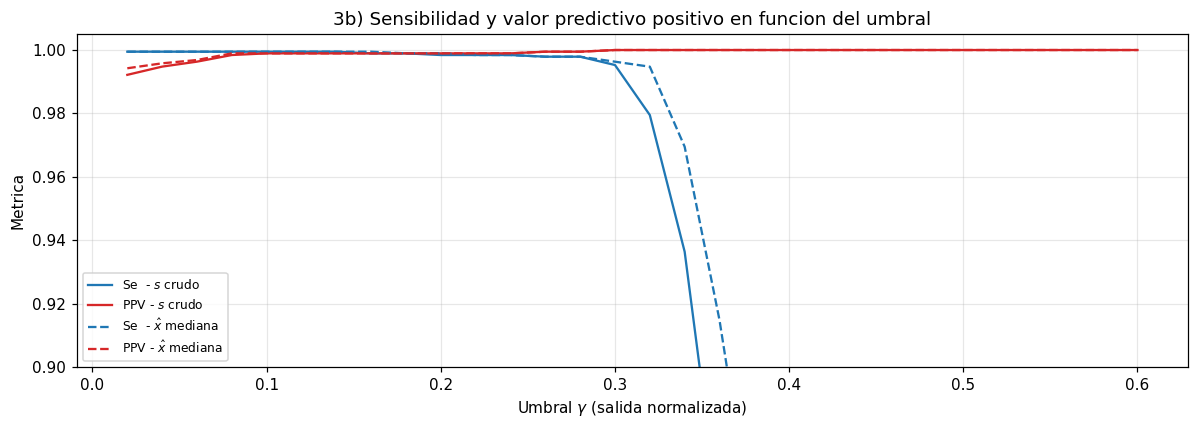

 umbral |       --- ECG crudo ---        | --- ECG sin linea de base --- 
        |    TP   FP   FN     Se     PPV |    TP   FP   FN     Se     PPV
   0.04 |  1902   10    1 0.9995  0.9948 |  1902    8    1 0.9995  0.9958
   0.10 |  1902    2    1 0.9995  0.9989 |  1902    2    1 0.9995  0.9989
   0.16 |  1901    2    2 0.9989  0.9989 |  1902    2    1 0.9995  0.9989
   0.20 |  1900    2    3 0.9984  0.9989 |  1901    2    2 0.9989  0.9989
   0.30 |  1894    0    9 0.9953  1.0000 |  1896    0    7 0.9963  1.0000
   0.40 |  1147    0  756 0.6027  1.0000 |  1406    0  497 0.7388  1.0000


In [13]:
umbrales = np.round(np.arange(0.02, 0.62, 0.02), 2)
res_s   = [evaluar(detectar(y_s,   u), qrs_det) for u in umbrales]
res_med = [evaluar(detectar(y_med, u), qrs_det) for u in umbrales]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(umbrales, [r['Se']  for r in res_s],   'C0-',  label='Se  - $s$ crudo')
ax.plot(umbrales, [r['PPV'] for r in res_s],   'C3-',  label='PPV - $s$ crudo')
ax.plot(umbrales, [r['Se']  for r in res_med], 'C0--', label=r'Se  - $\hat{x}$ mediana')
ax.plot(umbrales, [r['PPV'] for r in res_med], 'C3--', label=r'PPV - $\hat{x}$ mediana')
ax.set(title='3b) Sensibilidad y valor predictivo positivo en funcion del umbral',
       xlabel=r'Umbral $\gamma$ (salida normalizada)', ylabel='Metrica', ylim=(0.9, 1.005))
ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower left'); plt.tight_layout(); plt.show()

print(f'{"umbral":>7} | {"--- ECG crudo ---":^30} | {"--- ECG sin linea de base ---":^30}')
print(f'{"":>7} | {"TP":>5}{"FP":>5}{"FN":>5}{"Se":>7}{"PPV":>8} | {"TP":>5}{"FP":>5}{"FN":>5}{"Se":>7}{"PPV":>8}')
for u, a, b in zip(umbrales, res_s, res_med):
    if u in (0.04, 0.10, 0.16, 0.20, 0.30, 0.40):
        print(f'{u:7.2f} | {a["TP"]:5d}{a["FP"]:5d}{a["FN"]:5d}{a["Se"]:7.4f}{a["PPV"]:8.4f} | '
              f'{b["TP"]:5d}{b["FP"]:5d}{b["FN"]:5d}{b["Se"]:7.4f}{b["PPV"]:8.4f}')

Punto de operacion: umbral = 0.15, senal = ECG sin linea de base (mediana)
  TP = 1902   FP = 2   FN = 1
  Se = 99.95 %   PPV = 99.89 %   F1 = 99.92 %
  Posiciones FN: [248085]
  Posiciones FP: [247813 248619]


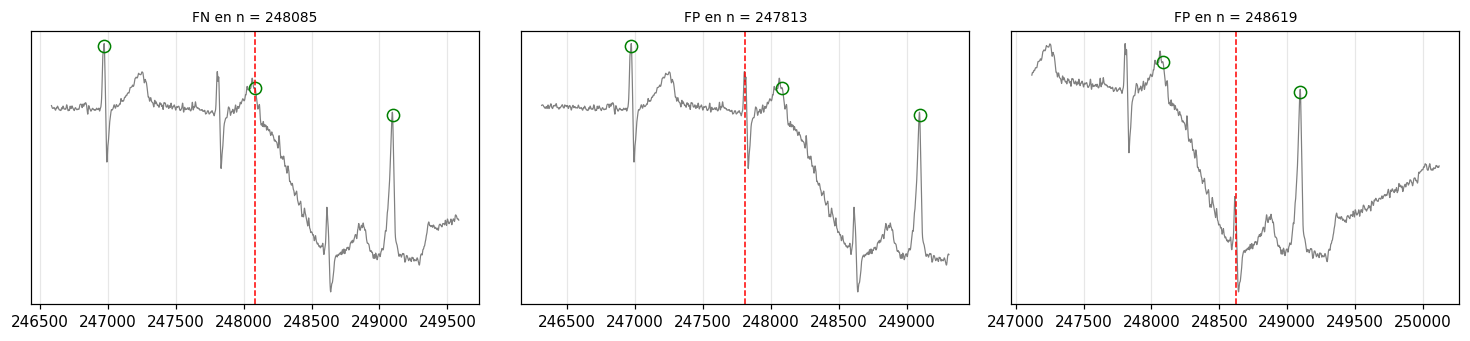

In [14]:
umbral_op = 0.15
r = evaluar(detectar(y_med, umbral_op), qrs_det)
print(f'Punto de operacion: umbral = {umbral_op}, senal = ECG sin linea de base (mediana)')
print(f'  TP = {r["TP"]}   FP = {r["FP"]}   FN = {r["FN"]}')
print(f'  Se = {100*r["Se"]:.2f} %   PPV = {100*r["PPV"]:.2f} %   F1 = {100*r["F1"]:.2f} %')
print(f'  Posiciones FN: {r["fn_pos"]}')
print(f'  Posiciones FP: {r["fp_pos"]}')

errores = list(r['fn_pos']) + list(r['fp_pos'])
fig, axes = plt.subplots(1, len(errores), figsize=(4.5*len(errores), 3.2), squeeze=False)
for ax, pos in zip(axes[0], errores):
    zz = np.arange(max(0, pos-1500), min(cant_muestras, pos+1500))
    ax.plot(zz, ecg_lead[zz], color='0.5', lw=0.8)
    rr = qrs_det[(qrs_det >= zz[0]) & (qrs_det <= zz[-1])]
    ax.plot(rr, ecg_lead[rr], 'go', ms=8, mfc='none')
    ax.axvline(pos, color='r', ls='--', lw=1)
    ax.set_title(('FN' if pos in r['fn_pos'] else 'FP') + f' en n = {pos}', fontsize=9)
    ax.set_yticks(()); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

El detector da Se y PPV de alrededor del 99.9 % para umbrales entre 0.08 y 0.3. Con umbrales bajos aparecen falsos positivos (ondas T altas, artefactos). Por encima de 0.3 la sensibilidad cae de golpe porque la salida está normalizada por el máximo y muchos latidos quedan con picos de 0.3 a 0.4; un umbral adaptativo lo resolvería. Restar antes la línea de base mejora apenas los resultados.

Los tres errores con el umbral elegido están en la misma zona (muestra 248000), donde hay un salto de línea de base: la referencia marca un latido en la bajada y el filtro detecta dos picos chicos a los costados. No queda claro cuál tiene razón. Además, `qrs_detections` sale de otro detector, así que lo que se mide es cuánto coinciden.

## Bonus - Estimación multirate de la línea de base

La línea de base está por debajo de 0.5 Hz, así que no hace falta calcularla a 1 kHz. Se baja la frecuencia de muestreo a 50 Hz ($D = 20$, con `sig.decimate`), se aplican las medianas (ahora de 11 y 31 muestras) y se vuelve a 1 kHz con splines.

In [15]:
D = 20
fs_d = fs // D

t0 = time.perf_counter()
ecg_d = sig.decimate(ecg_lead, D, ftype='fir', zero_phase=True)
b_d   = ndi.median_filter(ndi.median_filter(ecg_d, size=int(0.2*fs_d) | 1), size=int(0.6*fs_d) | 1)
b_mr  = CubicSpline(np.arange(len(b_d)) * D, b_d)(n)
t_mr  = time.perf_counter() - t0
x_mr  = ecg_lead - b_mr

pot_mr, iso_mr = metricas(x_mr)
pot_m,  iso_m  = metricas(x_med)
print(f'Mediana a tasa completa : {t_med:.3f} s   Pot<0.5Hz = {pot_m:.3e}   std nivel PQ = {iso_m:.1f}')
print(f'Mediana multirate (D={D}): {t_mr:.3f} s   Pot<0.5Hz = {pot_mr:.3e}   std nivel PQ = {iso_mr:.1f}')
print(f'Aceleracion: x{t_med/t_mr:.1f}')
print(f'RMS(b_multirate - b_mediana) = {np.sqrt(np.mean((b_mr-b_med)**2)):.0f}   (desvio del ECG = {ecg_lead.std():.0f})')

Mediana a tasa completa : 0.277 s   Pot<0.5Hz = 3.544e+04   std nivel PQ = 517.3
Mediana multirate (D=20): 0.115 s   Pot<0.5Hz = 3.625e+04   std nivel PQ = 540.5
Aceleracion: x2.4
RMS(b_multirate - b_mediana) = 128   (desvio del ECG = 4915)


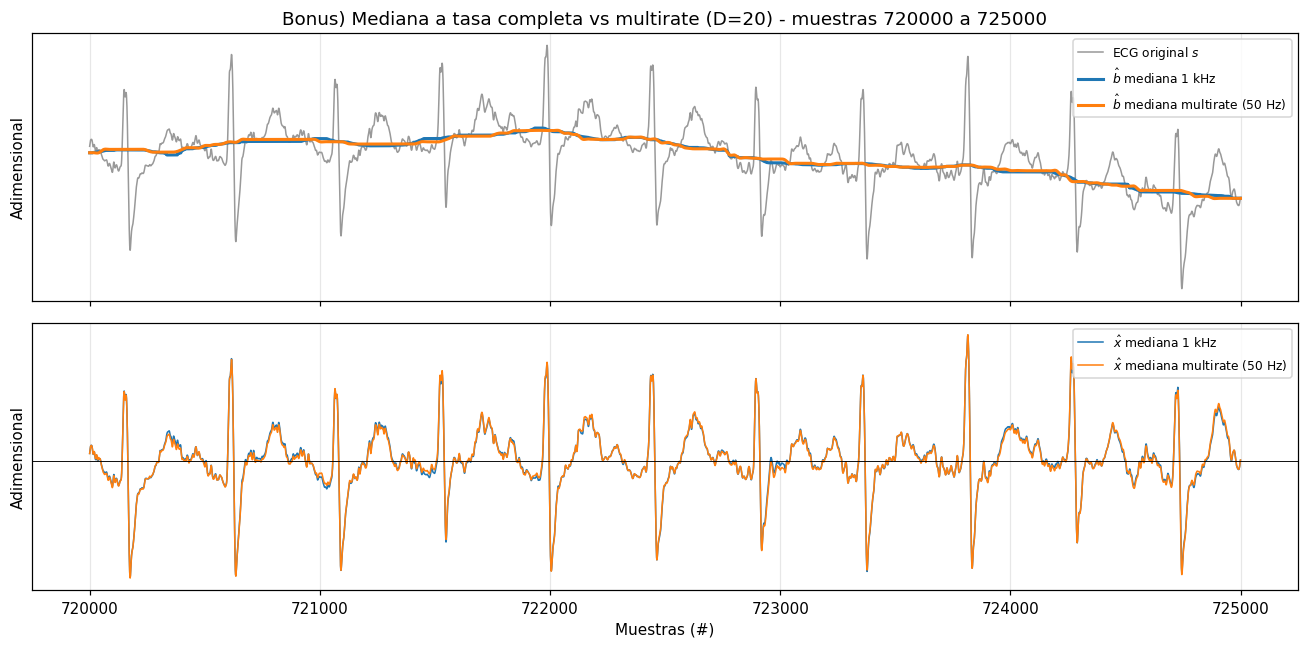

In [16]:
ii = [int(12*60*fs), int(12*60*fs) + 5000]
plot_region(ii, f'Bonus) Mediana a tasa completa vs multirate (D={D}) - muestras {ii[0]} a {ii[1]}',
            [('mediana 1 kHz', b_med, 'C0'), (f'mediana multirate ({fs_d} Hz)', b_mr, 'C1')])

El resultado es casi igual al de 1 kHz (la diferencia es del 3 % del desvío del ECG) y tarda menos. La mejora en tiempo es chica porque la mediana de scipy ya está optimizada; con un cálculo directo sería de unas $D^2 = 400$ veces.

## Conclusiones

Estimar y restar la línea de base funcionó mejor que el filtrado lineal de la TS7: la deriva baja entre 18 y 25 dB sin tocar el espectro del ECG, así que las ondas P y T se mantienen. La mediana solo necesita la señal pero su estimación se corre con frecuencia cardíaca alta; los splines siguen el nivel isoeléctrico real pero dependen de buenas detecciones. El filtro adaptado dio un detector con Se y PPV cercanos al 99.9 %, limitado por la forma y amplitud de los latidos. El enfoque multirate llega al mismo resultado con menos cálculo.